# Category Propensity Model

WitOmni · Break Through Tech AI Studio, Fall 2026

## What we're doing

We're building a deep learning model that predicts which product categories each customer is likely to buy next quarter. It runs on the UCI Online Retail data for WitOmni: about 500k transactions from roughly 4k customers.

The dataset has no product categories, so we make them ourselves with NLP by grouping about 4k product descriptions into 15–30 categories. The model then reads each customer's purchase history and outputs one probability per category: the chance they buy from it next quarter.

It's trained on all customers, so "will they come back at all" is already baked into every score. The point: "this customer will come back" is nice, but "this customer will probably buy candle holders" tells marketing exactly what to promote to whom.

## What the final product looks like

The output is one scored table with a row for every customer × category pair, and two ways to read it.

| Column | What it means |
| --- | --- |
| Customer ID | Who the score is for |
| Category | One of our NLP-built categories |
| Buy probability | Chance they buy from this category next quarter |
| Expected spend (£) | Buy probability × typical spend in that category, used for ranking |

- **Customer view:** pick a customer and see their category scores, highest first.
- **Campaign view:** pick a category and see customers ranked by expected spend. That's the list of who gets the promo.

The scores don't add up to 100%, since each category is its own yes/no and people buy several. We hand WitOmni the table as a CSV they can load into email or ad tools, plus a Streamlit demo with both views.

## Zero to hero

Already done in September: cleaning, EDA, and customer-level features. Everything below builds on that.

#### Data Cleaning

In [83]:
import os
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

In [84]:
df = pd.read_excel('https://raw.githubusercontent.com/Break-Through-Tech/witOmni-1A-ai-powered-customer-intelligence-for-smarter-marketing/main/data/Online%20Retail.xlsx', header=0)

In [85]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [86]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [87]:
df.shape

(541909, 8)

In [88]:
print("Duplicate rows: ", df.duplicated().sum())

Duplicate rows:  5268


In [89]:
df = df.drop_duplicates()

In [90]:
df.shape

(536641, 8)

In [91]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [92]:
# removing all the rows w/ missing customerID
df = df.dropna(subset=["CustomerID"])

In [93]:
print(df.isnull().sum())

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [94]:
# removing cancellation/returned items
df = df[~df["InvoiceNo"].astype(str).str.upper().str.startswith("C")]

In [95]:
# removing invalid transactions (invalid prices or quantities)
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]


In [96]:
# final statistics + check (doing it before dropping non relevant columns)
print(df.dtypes)
print(df.isnull().sum())
print("Duplicate rows: ", df.duplicated().sum())
print("Shape: ", df.shape)
df["CustomerID"] = df["CustomerID"].astype(int)

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64
Duplicate rows:  0
Shape:  (392692, 8)


In [97]:
#dropping non relevant columns
df = df.drop(columns=["Country"])

In [98]:
print("Final shape: ", df.shape)
print("\nMissing values: ")
print(df.isnull().sum())
print("\nData types: ")
print(df.dtypes)

Final shape:  (392692, 7)

Missing values: 
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
dtype: int64

Data types: 
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              int64
dtype: object


In [99]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850


In [100]:
import numpy as np
import pandas as pd

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


### 1. Lock the time split

Pick a cutoff date about 3 months before the data ends. Purchases before it are the history the model sees; categories bought after it are the labels. This keeps the model from peeking at the future.

In [101]:
# set CUTOFF_DATE       There is about 1 year worth of invoices from 12/2010 -> 12/2011
startdate = df["InvoiceDate"].min()
enddate = df["InvoiceDate"].max()
cutoff_date = startdate + (enddate - startdate) * 0.75

# months before and after the cutoff
months_before = (cutoff_date.year - startdate.year) * 12 + (cutoff_date.month - startdate.month)
months_after = (enddate.year - cutoff_date.year) * 12 + (enddate.month - cutoff_date.month) + 1

print(f"Data range:   {startdate.date()} -> {enddate.date()}")
print(f"Cutoff date:  {cutoff_date.date()}")
print()
print(f"Before cutoff: {months_before} months ({startdate.date()} -> {(cutoff_date - pd.Timedelta(days=1)).date()})")
print(f"After cutoff:  {months_after} months ({cutoff_date.date()} -> {enddate.date()})")
print()
print(f"Rows before cutoff: {(df['InvoiceDate'] < cutoff_date).sum():,}")
print(f"Rows after cutoff:  {(df['InvoiceDate'] >= cutoff_date).sum():,}")



Data range:   2010-12-01 -> 2011-12-09
Cutoff date:  2011-09-07

Before cutoff: 9 months (2010-12-01 -> 2011-09-06)
After cutoff:  4 months (2011-09-07 -> 2011-12-09)

Rows before cutoff: 230,209
Rows after cutoff:  162,483


In [102]:
history = df[df["InvoiceDate"] < cutoff_date].copy()
future = df[df["InvoiceDate"] >= cutoff_date].copy()

### 2. Build the categories with NLP

- Drop non-products (postage, fees, manual adjustments) and keep one description per StockCode.
- Strip color, pattern, and size words (RED, RETROSPOT, JUMBO) so items group by what they are, not how they look.
- Embed the descriptions with `all-MiniLM-L6-v2` and cluster them with KMeans.
- Have an LLM name each cluster, then merge or split by hand until there are 15–30 categories.
- Spot-check about 20 items per category, then save a `stockcode → category` CSV to the repo.

In [105]:
codes = df["StockCode"].astype(str).str.strip()
is_normal = codes.str.match(r"^\d{5}[A-Za-z]*$")


odd = (df[~is_normal]
       .groupby(codes[~is_normal])
       .agg(Description=("Description", "first"),
            rows=("StockCode", "size"),
            avg_price=("UnitPrice", "mean"))
       .sort_values("rows", ascending=False))
print(odd)


                             Description  rows   avg_price
StockCode                                                 
POST                             POSTAGE  1099   31.570482
M                                 Manual   279  178.406129
C2                              CARRIAGE   133   50.135338
DOT                       DOTCOM POSTAGE    16  744.147500
BANK CHARGES                Bank Charges    12   13.750083
PADS          PADS TO MATCH ALL CUSHIONS     3    0.001000


In [106]:
#filter out non-product StockCodes
df = df[is_normal]

In [107]:
df.sample(30)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
495102,578289,22742,MAKE YOUR OWN PLAYTIME CARD KIT,1,2011-11-23 14:07:00,2.95,17841
286062,562014,23200,JUMBO BAG PEARS,10,2011-08-01 14:05:00,2.08,14341
63544,541575,20719,WOODLAND CHARLOTTE BAG,2,2011-01-19 13:21:00,0.85,15311
61842,541488,22752,SET 7 BABUSHKA NESTING BOXES,28,2011-01-18 13:34:00,7.65,15061
67738,541844,22720,SET OF 3 CAKE TINS PANTRY DESIGN,1,2011-01-23 12:19:00,4.95,16931
61684,541480,84247L,FAWN AND MUSHROOM GREETING CARD,12,2011-01-18 12:05:00,0.42,12527
140438,548405,21175,GIN + TONIC DIET METAL SIGN,12,2011-03-31 09:48:00,2.55,17088
278052,561206,48173C,DOORMAT BLACK FLOCK,1,2011-07-25 16:18:00,7.95,13110
399623,571283,23089,GLASS BON BON JAR,2,2011-10-16 13:51:00,1.95,16533
353642,567818,23493,VINTAGE DOILY TRAVEL SEWING KIT,3,2011-09-22 12:41:00,1.95,14395


In [108]:
# !pip install sentence-transformers

# TODO: keep the most common description per StockCode done
# TODO: strip color / pattern / size words
# TODO: embed descriptions, cluster with KMeans
# TODO: name clusters, finalize 15–30 categories
# TODO: spot-check ~20 items per category
# TODO: save stockcode_to_category.csv

##### Keep most common description per StockCode

In [109]:
#147 out of 3580 stockcodes have more than 1 kind of description
description_counts = history.groupby("StockCode")["Description"].nunique()
print(description_counts.sum(),((description_counts > 1).sum()))

3586 147


In [110]:
#replace variable stock codes with most used description
product_desc = history.groupby("StockCode")["Description"].agg(lambda x: x.value_counts().idxmax())
history["Description"] = history["StockCode"].map(product_desc)

##### Strip color/pattern/size words

In [111]:
#remove colors
colorlist = [c.upper() for c in matplotlib.colors.CSS4_COLORS]
history["cleanedDescription"] = history["Description"].str.replace(r"\b(" + "|".join(colorlist) + r")\b", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()

In [112]:
history["Description"].str.split().explode().nunique()

2108

In [113]:
%pip install typesafe-sdk

In [ ]:
#use Jev to find pattern words
import os
from typesafe_sdk import TypeSafeClient, Noul

words = history["Description"].str.split().explode().dropna().unique().tolist()
pattern_words = []

with TypeSafeClient(api_key=os.getenv("TYPESAFE_API_KEY")) as client:
    for start in range(0, len(words), 20):
        batch = words[start:start + 20]
        questions = {f"w{i}": Noul(instructions=f"Is '{w}' a pattern word (like spotty, stripe, floral)?")
                     for i, w in enumerate(batch)}
        resp = client.system_one(state={"task": "Classify product description words"}, questions=questions)
        pattern_words += [w for i, w in enumerate(batch) if resp.nouls[f"w{i}"].noul > 0.8]

print(pattern_words)


['STARS', 'POLKADOT', 'SPOTTY', 'PAISLEY', 'GINGHAM', 'STRIPEY', 'SWIRLY', 'STRIPES', 'DOTS', 'SPOTS', 'HONEYCOMB', 'POLKA', 'CAMOUFLAGE', 'STRIPE', 'SPIRAL', 'SPOTTED', 'FLORAL', 'CAMO', 'CHECK', 'POLKADOTS', 'STRIPY', 'LATTICE', 'MOSAIC', 'GEOMETRIC', 'PATCHWORK']


In [114]:
pattern_words = ['STARS', 'POLKADOT', 'SPOTTY', 'PAISLEY', 'GINGHAM', 'STRIPEY', 'SWIRLY', 'STRIPES', 'DOTS', 'SPOTS', 'HONEYCOMB', 'POLKA', 'CAMOUFLAGE', 'STRIPE', 'SPIRAL', 'SPOTTED', 'FLORAL', 'CAMO', 'CHECK', 'POLKADOTS', 'STRIPY', 'LATTICE', 'MOSAIC', 'GEOMETRIC', 'PATCHWORK']

In [ ]:
#use Jev to find size words

size_words = []
with TypeSafeClient(api_key=os.getenv("TYPESAFE_API_KEY")) as client:
    for start in range(0, len(words), 20):
        batch = words[start:start + 20]
        questions = {f"w{i}": Noul(instructions=f"Is '{w}' a size word (like small, large, mini, jumbo)?")
                     for i, w in enumerate(batch)}
        resp = client.system_one(state={"task": "Classify product description words"}, questions=questions)
        size_words += [w for i, w in enumerate(batch) if resp.nouls[f"w{i}"].noul > 0.8]

print(size_words)


['MINI', 'LARGE', 'JUMBO', 'SMALL', 'GIANT', 'MED', 'LITTLE', 'MEDIUM', '"M"', 'BIG', 'PETIT', 'COMPACT', 'M', 'TINY', 'MINIATURE', 'L', '"L"']


In [115]:
size_words = ['MINI', 'LARGE', 'JUMBO', 'SMALL', 'GIANT', 'MED', 'LITTLE', 'MEDIUM', '"M"', 'BIG', 'PETIT', 'COMPACT', 'M', 'TINY', 'MINIATURE', 'L', '"L"']

In [118]:
import re

strip_words = size_words + pattern_words   # add + colorlist to remove colors too
regex = r"\b(" + "|".join(re.escape(w) for w in strip_words) + r")\b"

history["cleanedDescription"] = (history["cleanedDescription"]
                        .str.replace(regex, "", regex=True)
                        .str.replace(r"\s+", " ", regex=True)
                        .str.strip())


In [125]:
history["cleanedDescription"].sample(20)

,cleanedDescription
228729,LUNCH BAG SKULL.
33566,HEART WOODEN CHRISTMAS DECORATION
23224,HOT WATER BOTTLE BABUSHKA
73993,VANILLA CANDLE POT
295351,LUNCH BAG SKULL.
228036,SET 12 RETRO CHALK STICKS
210489,HEART FILIGREE DOVE
215346,ANTIQUE T-LIGHT GLASS
259081,SET OF 9 HEART SHAPED BALLOONS
199287,LUNCH BAG DOILEY PATTERN


In [127]:
print(history["Description"].nunique())

3408


##### embed descriptions

In [128]:
%pip install sentence-transformers

In [ ]:
#create a products table that stores each unique stockcode and its vector embedded description
from sentence_transformers import SentenceTransformer

products = history[["StockCode", "cleanedDescription"]].drop_duplicates("StockCode").reset_index(drop=True)
unique_desc = products["cleanedDescription"].unique().tolist()

model = SentenceTransformer("all-MiniLM-L6-v2")
vectors = model.encode(unique_desc, show_progress_bar=True, normalize_embeddings=True)

desc_to_vec = dict(zip(unique_desc, vectors))
X = np.vstack(products["cleanedDescription"].map(desc_to_vec))
print(X.shape)   # (number of products, 384)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

(3426, 384)


##### K-Means Clustering

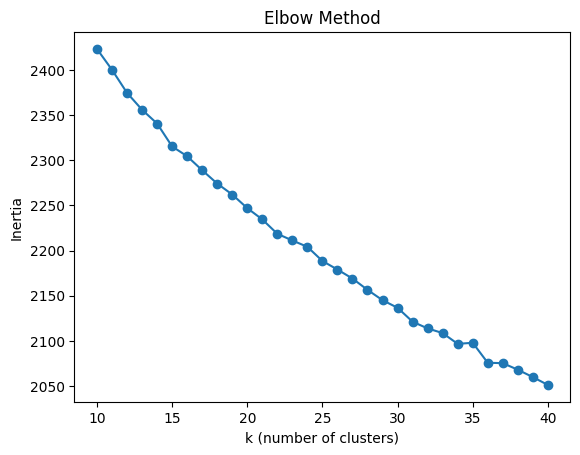

In [ ]:
#use elbow method to find best k

from sklearn.cluster import KMeans

ks = range(10, 41)
inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X).inertia_ for k in ks]

plt.plot(ks, inertias, marker="o")
plt.xlabel("k (number of clusters)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()


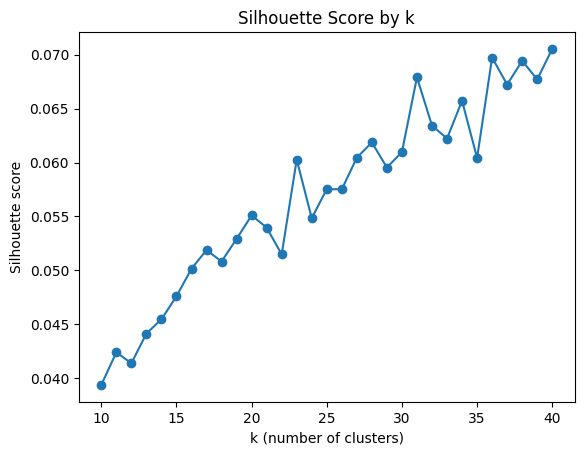

Best k: 40


In [131]:
from sklearn.metrics import silhouette_score

ks = range(10, 41)
scores = [silhouette_score(X, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)) for k in ks]

plt.plot(ks, scores, marker="o")
plt.xlabel("k (number of clusters)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score by k")
plt.show()

print("Best k:", ks[int(np.argmax(scores))])


In [141]:
kmeans = KMeans(n_clusters=23, random_state=42, n_init=10)
products["Cluster"] = kmeans.fit_predict(X)

for c in range(24):
    sample = products[products["Cluster"] == c]["cleanedDescription"].sample(min(10, (products["Cluster"] == c).sum()), random_state=42)
    print(f"\n--- Cluster {c} ({(products['Cluster'] == c).sum()} products) ---")
    print("\n".join(sample))



--- Cluster 0 (191 products) ---
HILDA CANDY SPOT RABBIT
SPACE CADET
BUDDHA HEAD
CLAM SHELL
COSY SLIPPER SHOES
FELTCRAFT DOLL MOLLY
DISCO BALL ROTATOR BATTERY OPERATED
COSY SLIPPER SHOES
JIGSAW TOADSTOOLS 3 PIECE
CHINESE STYLE SCISSOR

--- Cluster 1 (157 products) ---
FOUR RABBIT EASTER DECORATIONS
KNITTED EGG COSY
15 FLUFFY CHICKS IN BOX
HEN HOUSE W CHICK IN NEST
EASTER EGG HUNT START POST
BIRDS MOBILE VINTAGE DESIGN
CANDY SPOT EGG WARMER RABBIT
BUNNY DECORATION MAGIC GARDEN
CANDY SPOT EGG WARMER HARE
FLOWERS RABBIT EASTER

--- Cluster 2 (167 products) ---
FOLKART STAR CHRISTMAS DECORATIONS
ANGEL DECORATION WITH LACE PADDED
3D TRADITIONAL CHRISTMAS STICKERS
CHRISTMAS HANGING TREE WITH BELL
VINTAGE UNION JACK PENNANT
CHRISTMAS METAL TAGS ASSORTED
ANGEL DECORATION PAINTED ZINC
MAGIC CHRISTMAS TREE
PARTY CONES CANDY TREE DECORATION
DUSTY CHRISTMAS TREE 30CM

--- Cluster 3 (195 products) ---
CHERRY BLOSSOM CUP & SAUCER
HERB MARKER THYME
MIDNIGHT COPPER FLOWER NECKLAC
ORIGAMI SANDLEWOOD I

##### Cluster Names

In [139]:
cluster_names = {
    0: "Toys & Kids Gifts",
    1: "Easter & Spring Decor",
    2: "Christmas Decorations",
    3: "Floral & Garden",
    4: "Party & Baking Sets",
    5: "Bowls & Retrospot Homeware",
    6: "Mirrors & Photo Frames",
    7: "Furniture & Home Accents",
    8: "Candles & Incense",
    9: "Heart Decorations",
    10: "Kitchen & Baking",
    11: "Metal Signs",
    12: "Cushions & Soft Furnishings",
    13: "Hot Water Bottles & Bathroom",
    14: "Bags & Purses",
    15: "Gift Boxes, Cards & Wrap",
    16: "Jars, Glassware & Drawer Knobs",
    17: "Tea & Coffee",
    18: "Jewellery",
    19: "Furniture & Home Accents",   # number tiles merged into 7
    20: "T-Lights & Lamps",
    21: "Clocks",
    22: "Stationery & Crafts",
}


### 3. Build the training table

One row per customer: per-category history (how often, how recently, how much spent) plus RFM features. Labels are a yes/no per category for "bought after the cutoff."

In [ ]:
# TODO: per-category features from history (count, recency, spend)
# TODO: join RFM features from September
# TODO: labels = one 0/1 column per category from future purchases

### 4. Set up evaluation

Hold out a fixed set of test customers and fix the random seeds. Score with AUC per category and recall@k: were their real purchases in our top k guesses?

In [ ]:
# TODO: fixed train / test customer split (RANDOM_SEED)
# TODO: evaluate(scores, labels) -> AUC per category + recall@k

### 5. Build two baselines

First, "predict whatever they bought most." Second, LightGBM on customer × category rows. The deep learning model has to beat these to be worth it.

In [ ]:
# TODO: baseline 1 - rank categories by past purchase frequency
# TODO: baseline 2 - LightGBM on customer x category rows
# TODO: run both through evaluate()

### 6. Build the deep learning model

A neural net with one sigmoid output per category, not softmax, since people buy several. Optionally add a "buys anything" output. Tune lightly (layers, dropout, learning rate) and use early stopping.

In [ ]:
# TODO: MLP with one sigmoid output per category (+ optional "buys anything")
# TODO: train with early stopping, light tuning
# TODO: run through evaluate()

### 7. Stretch: sequence model

A GRU or transformer that reads each customer's orders in order. Only if step 6 works and there's time left.

In [ ]:
# TODO (stretch): sequence model over each customer's ordered purchases

### 8. Compare and sanity-check

Run the deep learning model against the baselines on the same test customers. Near-perfect scores mean something's leaking. A tie with the baseline is still a legit finding.

In [ ]:
# TODO: comparison table of all models on the same test customers

### 9. Calibrate

Plot a calibration curve. If "60%" doesn't actually mean 60%, add a calibration step.

In [ ]:
# TODO: calibration curve per category (or pooled)
# TODO: calibrate if needed

### 10. Ship it

Score every customer × category, export the CSV, and build the Streamlit demo. Write up the findings and the caveats: category accuracy from the spot-check, and the test window landing in the holiday rush.

In [ ]:
# TODO: score every customer x category -> buy probability + expected spend
# TODO: export scored CSV

## Extension: combining with the team's repeat-purchaser model

### What we're doing

The team's model predicts who comes back; mine predicts what they'll buy. To combine them, the category model is retrained on returning customers only, so its scores mean "which categories, given they come back." Then:

$$P(\text{buys category}) = P(\text{returns}) \times P(\text{category} \mid \text{returns})$$

The win isn't accuracy, since the standalone model already bakes in returning. It's having a separate return score that powers the marketing playbook below.

### What the final product looks like

The same scored table and two views, plus a return probability column. Every customer also lands in one playbook segment:

| | Clear category preference | No clear preference |
| --- | --- | --- |
| **Likely to return** | Targeted promo for their top category | New arrivals or general loyalty offer |
| **Unlikely to return** | Win-back using the category they love | Don't spend money here |

The bottom-left box is the gold: customers drifting away, but we know exactly what might pull them back.

### Zero to hero

1. **Align with the team.** Same cutoff date and same test customers. Otherwise the combined scores are quietly inflated.
2. **Retrain on returners.** Same pipeline as the standalone model, with one filter: only customers who bought again after the cutoff.
3. **Pull the team's scores.** Get their return probability for every customer.
4. **Calibrate both.** Multiplying two miscalibrated probabilities stacks the error.
5. **Combine.** Multiply the two scores, then multiply by typical category spend to get expected spend.
6. **Segment.** Place each customer in the playbook using their return score and how concentrated their category scores are.
7. **Ship it.** Add the return probability and segment to the CSV and both demo views.

In [ ]:
# TODO: confirm cutoff date + test customers match the team's
# TODO: retrain category model on returners only
# TODO: load team's return probabilities
# TODO: calibrate both, combine, compute expected spend
# TODO: assign playbook segments, add to CSV + demo